# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import EAGLEDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 318


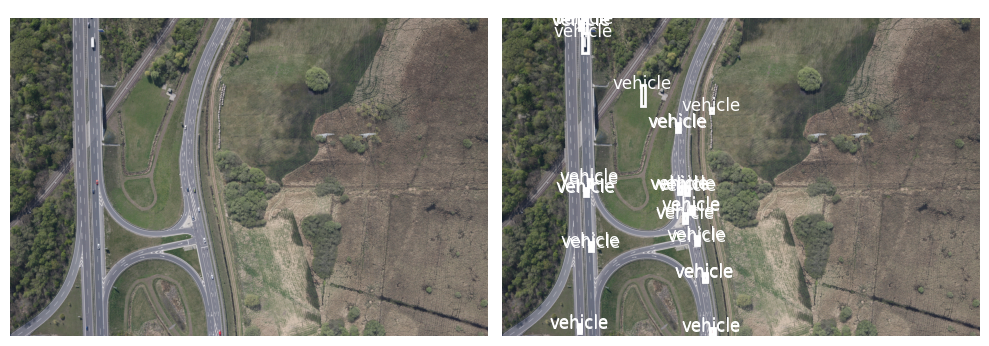

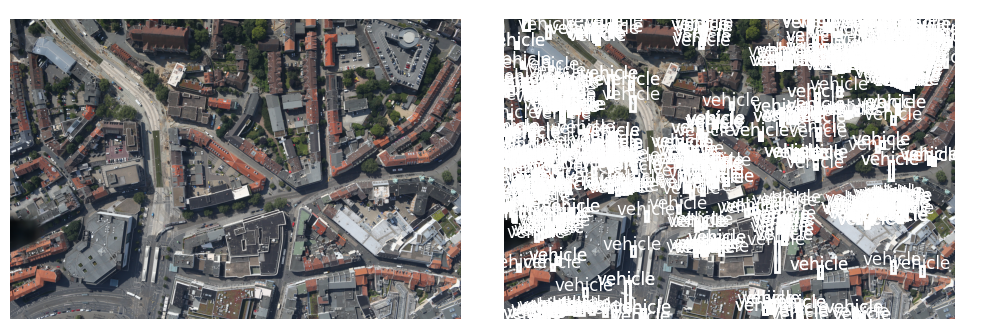

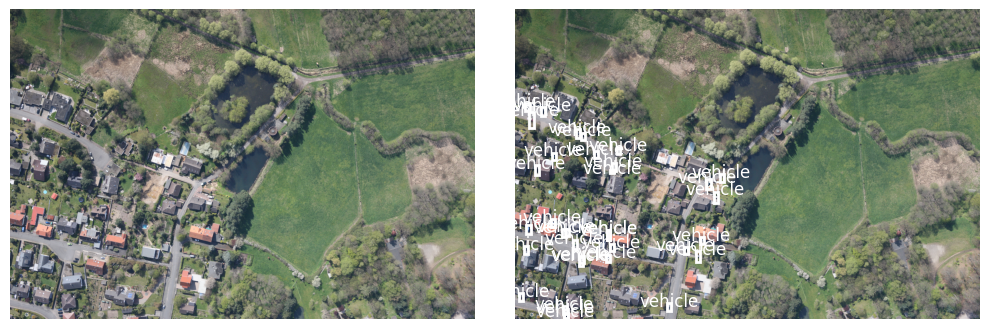

In [82]:
dataset_config = {
    "image_dir": "/home/dragik/data/FAIR_EO/EAGLE/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/EAGLE/label_xmls/",
}
dataset = EAGLEDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(30);
dataset.show_image(90);

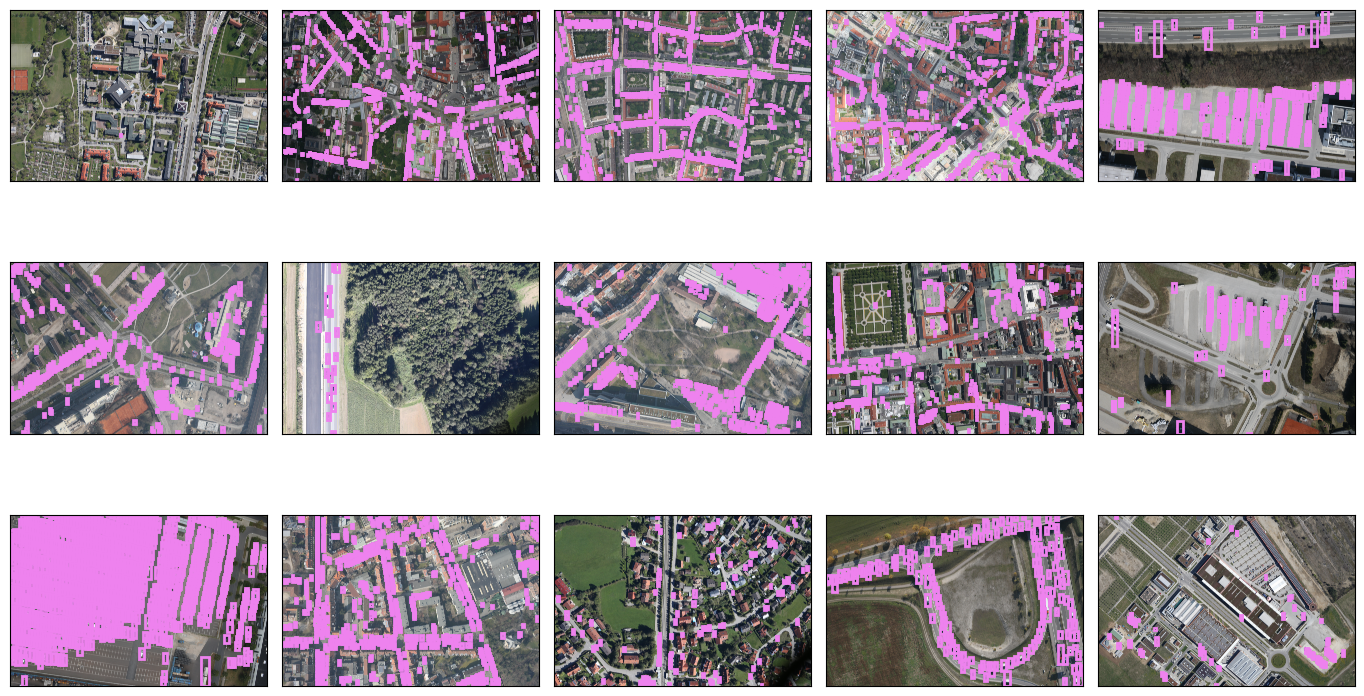

In [83]:
dataset.show_batch(15);

In [84]:
dataset.data_distribution_table()

,Label,Count
0,vehicle,194676


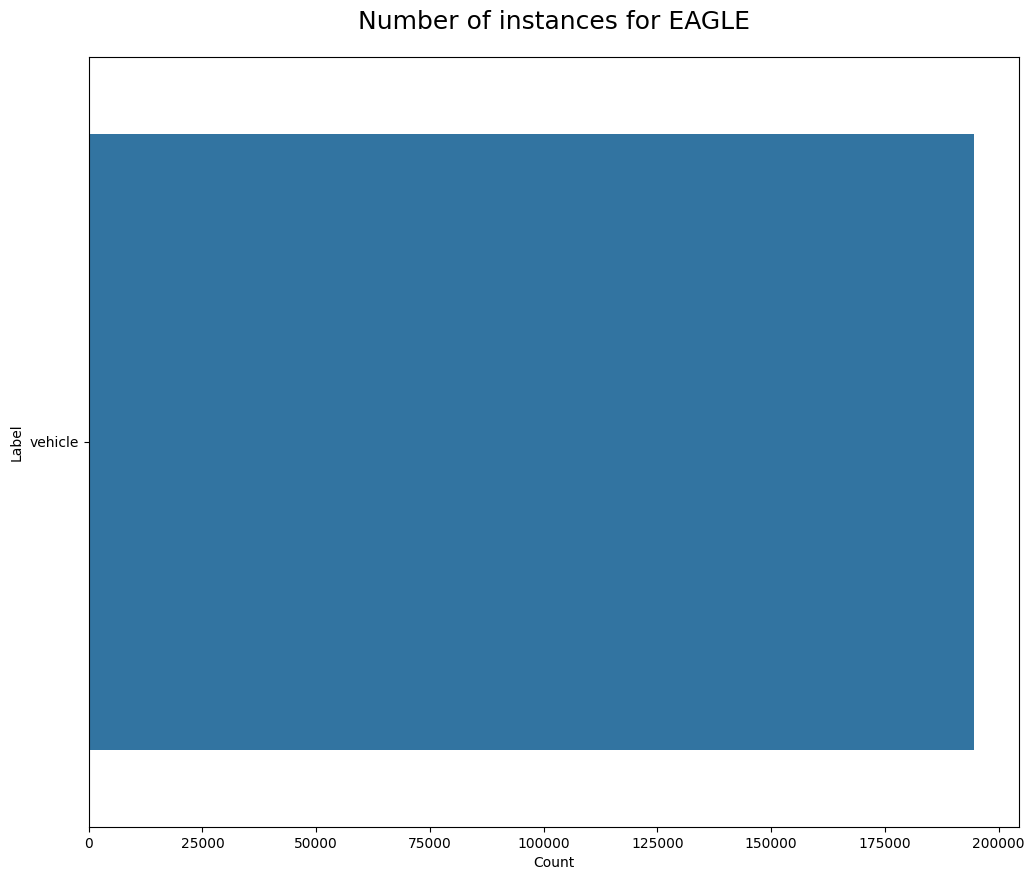

In [85]:
dataset.data_distribution_barchart();

## Load train data

In [6]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "image_dir": "/home/dragik/data/FAIR_EO/EAGLE/Train/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/EAGLE/Train/label_xmls/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = EAGLEDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 144


## Create the model

In [7]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/EAGLE/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [8]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-26 07:22:28,723 INFO Starting training.
training: 100%|██████████| 18/18 [01:05<00:00,  3.63s/it]
2025-05-26 07:23:34,518 INFO epoch: 1, time: 65, loss:  2.74025
testing on train set: 100%|██████████| 18/18 [01:34<00:00,  5.25s/it]
2025-05-26 07:27:17,740 INFO map:0.0013415418798103929, map_50:0.004925774876028299, map_75:8.136085671139881e-05, map_small:0.0013422577176243067, map_medium:0.0, map_large:-1.0, mar_1:9.75473813014105e-05, mar_10:0.0007246377062983811, mar_100:0.0037980135530233383, mar_small:0.0038012401200830936, mar_medium:0.0, mar_large:-1.0, map_per_class:0.0013415418798103929, mar_100_per_class:0.0037980135530233383, classes:1.0
training: 100%|██████████| 18/18 [01:12<00:00,  4.00s/it]
2025-05-26 07:28:29,756 INFO epoch: 2, time: 72, loss:  1.31426
testing on train set: 100%|██████████| 18/18 [01:19<00:00,  4.43s/it]
2025-05-26 07:31:59,405 INFO map:0.0036554778926074505, map_50:0.013039903715252876, map_75:0.0010720817372202873, map_small:0.00365773681551218

## Evaluate the model

In [9]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "/home/dragik/data/FAIR_EO/EAGLE/Val/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/EAGLE/Val/label_xmls/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = EAGLEDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/EAGLE/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 44


2025-05-26 08:17:03,793 INFO Loading checkpoint /home/dragik/data/FAIR_EO/EAGLE/experiments/checkpoint.pth.tar
2025-05-26 08:17:04,193 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/EAGLE/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 6/6 [00:13<00:00,  2.19s/it]


[{'map': 0.022831354290246964,
  'map_50': 0.05455821752548218,
  'map_75': 0.01655600778758526,
  'map_small': 0.0228563342243433,
  'map_medium': 0.003646864788606763,
  'map_large': -1.0,
  'mar_1': 0.0006352046621032059,
  'mar_10': 0.005792887415736914,
  'mar_100': 0.027345113456249237,
  'mar_small': 0.027341477572917938,
  'mar_medium': 0.03750000149011612,
  'mar_large': -1.0,
  'map_per_class': 0.022831354290246964,
  'mar_100_per_class': 0.027345113456249237,
  'classes': 1.0}]

## Predictions

2025-05-26 08:19:33,581 INFO Loading checkpoint /home/dragik/data/FAIR_EO/EAGLE/experiments/checkpoint.pth.tar
2025-05-26 08:19:33,969 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/EAGLE/experiments/checkpoint.pth.tar at epoch 11


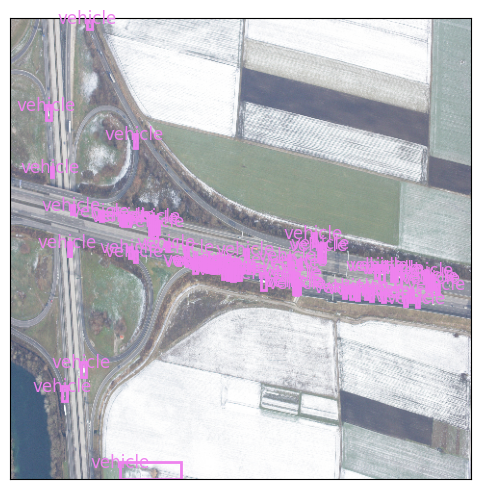

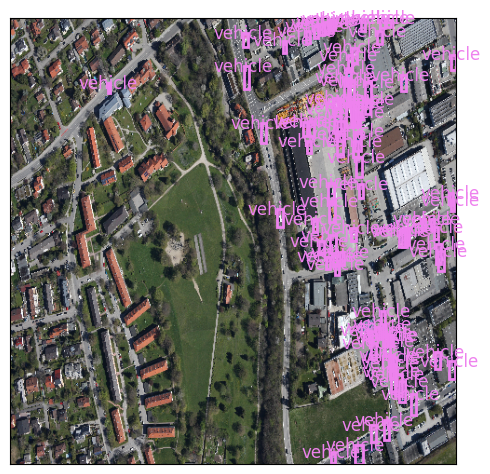

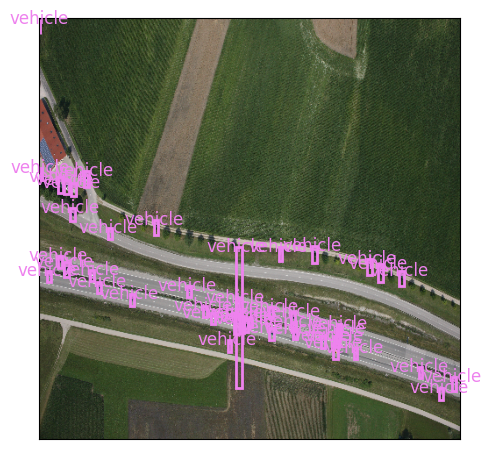

In [11]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/EAGLE/experiments/checkpoint.pth.tar"
labels = ['no-data','vehicle']
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/EAGLE/Test/images/2008-11-28-Muenchen-Verkehr-mitte-yp3x0292.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/EAGLE/Test/images/2012-04-26-Muenchen-Tunnel_4K0G0060.JPG')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/EAGLE/Test/images/2014-07-25-Chicago--mitte-S0969.jpg')
fig = model.detect_objects(image, labels, transform)